In [1]:
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt

In [2]:
def gaussian_kernel_5(sigma=1.0):
    k = np.zeros((5, 5), dtype=np.float64)
    for y in range(-2, 3):
        for x in range(-2, 3):
            k[y + 2, x + 2] = math.exp(-(x * x + y * y) / (2 * sigma * sigma))
    return k / k.sum()


def convolve_zero(image, kernel):
    src = np.asarray(image, dtype=np.float64)
    k = np.asarray(kernel, dtype=np.float64)
    kh, kw = k.shape
    ph, pw = kh // 2, kw // 2

    padded = np.zeros((src.shape[0] + 2 * ph, src.shape[1] + 2 * pw), dtype=np.float64)
    padded[ph : ph + src.shape[0], pw : pw + src.shape[1]] = src

    out = np.zeros_like(src)

    for y in range(src.shape[0]):
        for x in range(src.shape[1]):
            total = 0.0
            for ky in range(kh):
                for kx in range(kw):
                    total += padded[y + ky, x + kx] * k[ky, kx]
            out[y, x] = total
    return out


def canny_manual(gray, low, high):
    smooth = convolve_zero(gray, gaussian_kernel_5(1.0))

    sx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
    sy = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float)

    gx, gy = convolve_zero(smooth, sx), convolve_zero(smooth, sy)

    mag = np.sqrt(gx * gx + gy * gy)
    angle = np.degrees(np.arctan2(gy, gx))
    angle = np.mod(angle, 180.0)

    nms = np.zeros_like(mag)
    h, w = mag.shape

    for y in range(1, h - 1):
        for x in range(1, w - 1):
            a = angle[y, x]
            if a < 22.5 or a >= 157.5:
                p, q = mag[y, x - 1], mag[y, x + 1]
            elif a < 67.5:
                p, q = mag[y - 1, x + 1], mag[y + 1, x - 1]
            elif a < 112.5:
                p, q = mag[y - 1, x], mag[y + 1, x]
            else:
                p, q = mag[y - 1, x - 1], mag[y + 1, x + 1]

            if mag[y, x] >= p and mag[y, x] >= q:
                nms[y, x] = mag[y, x]

    state = np.zeros((h, w), dtype=np.uint8)
    state[(nms >= low) & (nms < high)] = 1
    state[nms >= high] = 2

    edges = np.zeros((h, w), dtype=np.uint8)
    stack = [(int(y), int(x)) for y, x in zip(*np.nonzero(state == 2))]
    for y, x in stack:
        edges[y, x] = 255

    while stack:
        y, x = stack.pop()
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                ny, nx = y + dy, x + dx
                if 0 <= ny < h and 0 <= nx < w and state[ny, nx] == 1:
                    state[ny, nx] = 2
                    edges[ny, nx] = 255
                    stack.append((ny, nx))
    return smooth, mag, nms, edges

In [3]:
messi = cv2.imread("messi.png", cv2.IMREAD_GRAYSCALE)
messi.shape
low_t, high_t = 100, 200
messi_smoothed, mag, nms, fin = canny_manual(messi.copy(), low_t, high_t)

(np.float64(-0.5), np.float64(547.5), np.float64(341.5), np.float64(-0.5))

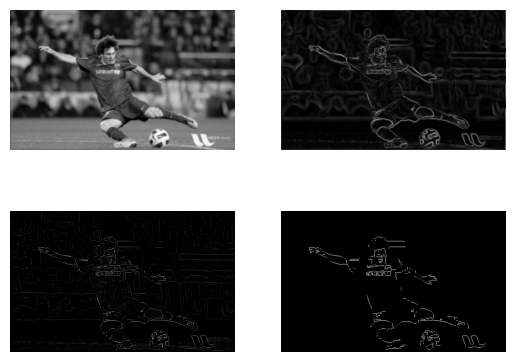

In [4]:
plt.subplot(2, 2, 1)
plt.imshow(messi_smoothed, cmap="gray")
plt.axis("off")
plt.subplot(2, 2, 2)
plt.imshow(mag, cmap="gray")
plt.axis("off")
plt.subplot(2, 2, 3)
plt.imshow(nms, cmap="gray")
plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(fin, cmap="gray")
plt.axis("off")

# Q2


In [5]:
def hough_lines(edge, vote_threshold=100):
    h, w = edge.shape

    rho_max = int(math.ceil(math.sqrt(h * h + w * w)))
    thetas = np.arange(180)

    cos_t = np.cos(np.deg2rad(thetas))
    sin_t = np.sin(np.deg2rad(thetas))

    acc = np.zeros((2 * rho_max + 1, 180), dtype=np.uint32)

    ys, xs = np.nonzero(edge)

    for y, x in zip(ys, xs):
        for ti in range(180):
            rho = int(round(x * cos_t[ti] + y * sin_t[ti]))
            acc[rho + rho_max, ti] += 1

    peaks = []
    for ri in range(acc.shape[0]):
        for ti in range(180):
            if acc[ri, ti] >= vote_threshold:
                peaks.append((ri - rho_max, ti, int(acc[ri, ti])))
    return acc, peaks


def paint_hough_lines(rgb, peaks):
    out = rgb.copy()

    h, w = out.shape[:2]

    for rho, theta, _votes in peaks:
        t = math.radians(theta)
        ct, st = math.cos(t), math.sin(t)
        pts = []

        if abs(st) > 1e-12:
            for x in (0, w - 1):
                y = (rho - x * ct) / st
                if 0 <= y < h:
                    pts.append((int(round(x)), int(round(y))))

        if abs(ct) > 1e-12:
            for y in (0, h - 1):
                x = (rho - y * st) / ct
                if 0 <= x < w:
                    pts.append((int(round(x)), int(round(y))))

        # Remove duplicate intersections while preserving order.
        pts = list(dict.fromkeys(pts))
        if len(pts) < 2:
            continue
        x0, y0 = pts[0]
        x1, y1 = pts[1]
        steps = max(abs(x1 - x0), abs(y1 - y0), 1)
        
        for i in range(steps + 1):
            x = int(round(x0 + (x1 - x0) * i / steps))
            y = int(round(y0 + (y1 - y0) * i / steps))
            if 0 <= y < h and 0 <= x < w:
                out[y, x] = [255, 0, 0]
    return out

In [6]:
sudoku = cv2.imread("sudoku.png", cv2.IMREAD_GRAYSCALE)
sudoku_rgb = cv2.imread("sudoku.png")
_, _, _, sudoku_edges = canny_manual(sudoku, 50, 150)

accumulator, line_peaks = hough_lines(sudoku_edges, 100)
sudoku_lines = paint_hough_lines(sudoku_rgb, line_peaks)

(np.float64(-0.5), np.float64(449.5), np.float64(449.5), np.float64(-0.5))

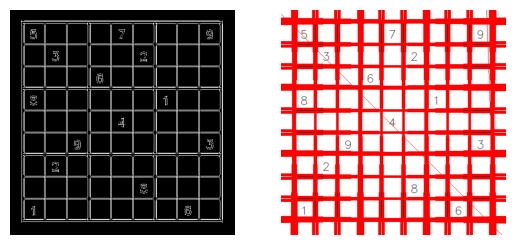

In [7]:
plt.subplot(1, 2, 1)
plt.imshow(sudoku_edges, cmap="gray")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sudoku_lines, cmap="gray")
plt.axis("off")

# Q3

HORIZONTAL RLC
Total runs: 6247 | Compressed bits: 56223
Compression ratio: 1.1656 | Bits per pixel: 0.8579
Exact reconstruction: True
VERTICAL RLC
Total runs: 6629 | Compressed bits: 59661
Compression ratio: 1.0985 | Bits per pixel: 0.9104
Exact reconstruction: True


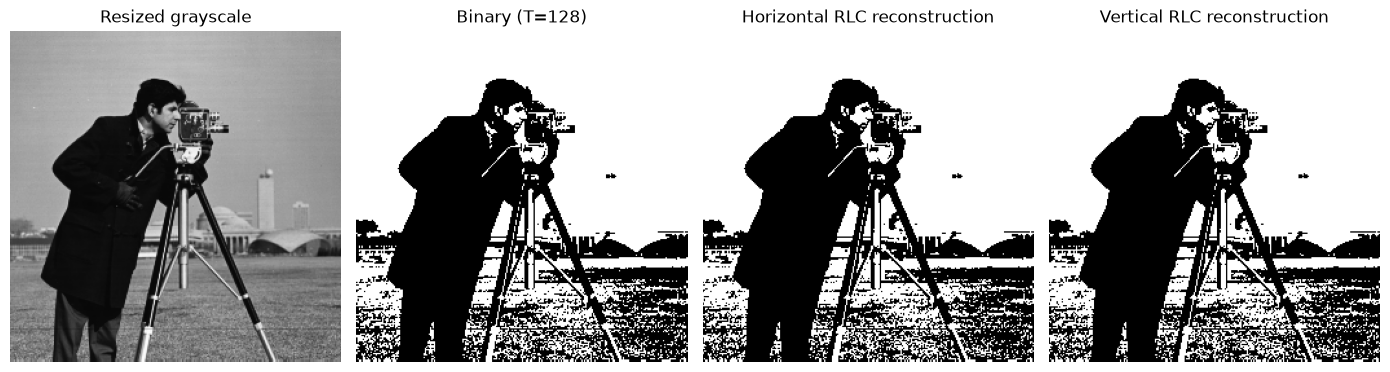

In [8]:
def encode_runs(sequence):
    runs = []
    bit = 0
    length = 0
    for value in sequence:
        value = int(value)
        if value == bit:
            length += 1
        else:
            runs.append(length)
            bit = value
            length = 1
    runs.append(length)
    return runs


def decode_runs(runs, length):
    out = np.zeros(length, dtype=np.uint8)
    position = 0
    bit = 0
    for run in runs:
        end = position + run
        if bit == 1:
            out[position:end] = 1
        position = end
        bit = 1 - bit

    return out


def encode_image(binary, direction):
    h, w = binary.shape
    lines = binary if direction == "horizontal" else binary.T
    return [encode_runs(line) for line in lines]


def decode_image(encoded, direction, shape):
    h, w = shape
    line_length = w if direction == "horizontal" else h
    decoded_lines = np.stack([decode_runs(runs, line_length) for runs in encoded])
    return decoded_lines if direction == "horizontal" else decoded_lines.T


def rlc_metrics(encoded, pixel_count):
    total_runs = sum(len(line) for line in encoded)
    compressed_bits = 9 * total_runs
    original_bits = pixel_count
    return (
        total_runs,
        compressed_bits,
        original_bits / compressed_bits,
        compressed_bits / pixel_count,
    )


def resize_bilinear(image, out_h, out_w):
    src = np.asarray(image, dtype=np.float64)

    in_h, in_w = src.shape[:2]

    out = np.zeros((out_h, out_w), dtype=np.float64)

    for r in range(out_h):
        y = (r + 0.5) * in_h / out_h - 0.5
        y = min(max(y, 0.0), in_h - 1.0)
        y0, y1 = int(y), min(int(y) + 1, in_h - 1)
        dy = y - y0

        for c in range(out_w):
            x = (c + 0.5) * in_w / out_w - 0.5
            x = min(max(x, 0.0), in_w - 1.0)
            x0, x1 = int(x), min(int(x) + 1, in_w - 1)
            dx = x - x0

            out[r, c] = (1 - dy) * ((1 - dx) * src[y0, x0] + dx * src[y0, x1])
            +dy * ((1 - dx) * src[y1, x0] + dx * src[y1, x1])

    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def show_gray(images, titles, figsize=(15, 4)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    if len(images) == 1:
        axes = [axes]
    for ax, im, title in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


camera_gray = cv2.imread("cameraman.tif", cv2.IMREAD_GRAYSCALE)
camera_256 = resize_bilinear(camera_gray, 256, 256)

camera_binary = (camera_256 >= 128).astype(np.uint8)

h_runs = encode_image(camera_binary, "horizontal")
v_runs = encode_image(camera_binary, "vertical")
h_recon = decode_image(h_runs, "horizontal", camera_binary.shape)
v_recon = decode_image(v_runs, "vertical", camera_binary.shape)
for label, encoded, reconstructed in [
    ("HORIZONTAL", h_runs, h_recon),
    ("VERTICAL", v_runs, v_recon),
]:
    runs, bits, cr, bpp = rlc_metrics(encoded, camera_binary.size)
    print(f"{label} RLC")
    print("Total runs:", runs, "| Compressed bits:", bits)
    print(f"Compression ratio: {cr:.4f} | Bits per pixel: {bpp:.4f}")
    print("Exact reconstruction:", bool(np.array_equal(camera_binary, reconstructed)))

show_gray(
    [camera_256, camera_binary * 255, h_recon * 255, v_recon * 255],
    [
        "Resized grayscale",
        "Binary (T=128)",
        "Horizontal RLC reconstruction",
        "Vertical RLC reconstruction",
    ],
    figsize=(14, 4),
)